In [1]:
import torch
from diffusion_networks import SongUNet
from dataset import SQGLeadTimeDataset, DATA_500
from torch.utils.data import DataLoader



model = SongUNet(
        img_resolution     = 64,
        in_channels        = 2 * 2,  # 2 (z_s) + 2 (x_t conditioning)
        out_channels       = 2,
        embedding_type     = 'positional',
        encoder_type       = 'residual',
        decoder_type       = 'standard',
        channel_mult_noise = 2,
        resample_filter    = [1, 3, 3, 1],
        channel_mult       = [2, 2, 2],
        attn_resolutions   = [32],
        time_emb           = 1,                 # must be 1 for lead-time conditioning
    )


In [2]:
model.enc

ModuleDict(
  (64x64_conv): Conv2d()
  (64x64_block0): UNetBlock(
    (norm0): GroupNorm()
    (conv0): Conv2d()
    (affine): Linear()
    (norm1): GroupNorm()
    (conv1): Conv2d()
    (skip): Conv2d()
  )
  (64x64_block1): UNetBlock(
    (norm0): GroupNorm()
    (conv0): Conv2d()
    (affine): Linear()
    (norm1): GroupNorm()
    (conv1): Conv2d()
  )
  (64x64_block2): UNetBlock(
    (norm0): GroupNorm()
    (conv0): Conv2d()
    (affine): Linear()
    (norm1): GroupNorm()
    (conv1): Conv2d()
  )
  (64x64_block3): UNetBlock(
    (norm0): GroupNorm()
    (conv0): Conv2d()
    (affine): Linear()
    (norm1): GroupNorm()
    (conv1): Conv2d()
  )
  (32x32_down): UNetBlock(
    (norm0): GroupNorm()
    (conv0): Conv2d()
    (affine): Linear()
    (norm1): GroupNorm()
    (conv1): Conv2d()
    (skip): Conv2d()
  )
  (32x32_aux_residual): Conv2d()
  (32x32_block0): UNetBlock(
    (norm0): GroupNorm()
    (conv0): Conv2d()
    (affine): Linear()
    (norm1): GroupNorm()
    (conv1): Con

In [3]:
model.dec

ModuleDict(
  (16x16_in0): UNetBlock(
    (norm0): GroupNorm()
    (conv0): Conv2d()
    (affine): Linear()
    (norm1): GroupNorm()
    (conv1): Conv2d()
    (norm2): GroupNorm()
    (qkv): Conv2d()
    (proj): Conv2d()
  )
  (16x16_in1): UNetBlock(
    (norm0): GroupNorm()
    (conv0): Conv2d()
    (affine): Linear()
    (norm1): GroupNorm()
    (conv1): Conv2d()
  )
  (16x16_block0): UNetBlock(
    (norm0): GroupNorm()
    (conv0): Conv2d()
    (affine): Linear()
    (norm1): GroupNorm()
    (conv1): Conv2d()
    (skip): Conv2d()
  )
  (16x16_block1): UNetBlock(
    (norm0): GroupNorm()
    (conv0): Conv2d()
    (affine): Linear()
    (norm1): GroupNorm()
    (conv1): Conv2d()
    (skip): Conv2d()
  )
  (16x16_block2): UNetBlock(
    (norm0): GroupNorm()
    (conv0): Conv2d()
    (affine): Linear()
    (norm1): GroupNorm()
    (conv1): Conv2d()
    (skip): Conv2d()
  )
  (16x16_block3): UNetBlock(
    (norm0): GroupNorm()
    (conv0): Conv2d()
    (affine): Linear()
    (norm1): Gro

In [4]:
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
non_trainable = sum(p.numel() for p in model.parameters() if not p.requires_grad)
print(f"Trainable: {trainable}, Non-trainable: {non_trainable}")

Trainable: 56396674, Non-trainable: 0


In [8]:
from collections import defaultdict

sector_params = defaultdict(int)
sector_layers = defaultdict(set)
updown_params = defaultdict(int)
updown_layers = defaultdict(set)

for name, param in model.named_parameters():

    parts = name.split(".")
    if parts[0] in ("enc", "dec"):
        sector, layer = parts[0], parts[1]
    else:
        sector, layer = "mapping", parts[0]

    sector_params[sector] += param.numel()
    sector_layers[sector].add(layer)

    if sector in ("enc", "dec"):
        if "_down" in layer:
            key = (sector, "down")
        elif "_up" in layer:
            key = (sector, "up")
        else:
            key = None
        if key is not None:
            updown_params[key] += param.numel()
            updown_layers[key].add(layer)

print("-- sector summary ---")
for sector in sector_params:
    print(f"{sector}: layers={len(sector_layers[sector])}, params={sector_params[sector]}")

print("-- up/down summary ---")
for (sector, kind), params in updown_params.items():
    print(f"{sector} {kind}: layers={len(updown_layers[(sector, kind)])}, params={params}")

-- sector summary ---
mapping: layers=2, params=394240
enc: layers=17, params=19903616
dec: layers=21, params=36098818
-- up/down summary ---
enc down: layers=2, params=2756608
dec up: layers=2, params=2756608


In [2]:
dataset = SQGLeadTimeDataset(DATA_500)
dataloader = DataLoader(dataset, batch_size=64)
len(dataloader) * 64

760000

In [3]:
val_dataset = SQGLeadTimeDataset(DATA_500, split='val')
val_dataloader = DataLoader(val_dataset, batch_size=64)
len(val_dataloader) * 64

190016

In [5]:
ts = torch.linspace(1, 0, 100 + 1)
ts

tensor([1.0000, 0.9900, 0.9800, 0.9700, 0.9600, 0.9500, 0.9400, 0.9300, 0.9200,
        0.9100, 0.9000, 0.8900, 0.8800, 0.8700, 0.8600, 0.8500, 0.8400, 0.8300,
        0.8200, 0.8100, 0.8000, 0.7900, 0.7800, 0.7700, 0.7600, 0.7500, 0.7400,
        0.7300, 0.7200, 0.7100, 0.7000, 0.6900, 0.6800, 0.6700, 0.6600, 0.6500,
        0.6400, 0.6300, 0.6200, 0.6100, 0.6000, 0.5900, 0.5800, 0.5700, 0.5600,
        0.5500, 0.5400, 0.5300, 0.5200, 0.5100, 0.5000, 0.4900, 0.4800, 0.4700,
        0.4600, 0.4500, 0.4400, 0.4300, 0.4200, 0.4100, 0.4000, 0.3900, 0.3800,
        0.3700, 0.3600, 0.3500, 0.3400, 0.3300, 0.3200, 0.3100, 0.3000, 0.2900,
        0.2800, 0.2700, 0.2600, 0.2500, 0.2400, 0.2300, 0.2200, 0.2100, 0.2000,
        0.1900, 0.1800, 0.1700, 0.1600, 0.1500, 0.1400, 0.1300, 0.1200, 0.1100,
        0.1000, 0.0900, 0.0800, 0.0700, 0.0600, 0.0500, 0.0400, 0.0300, 0.0200,
        0.0100, 0.0000])

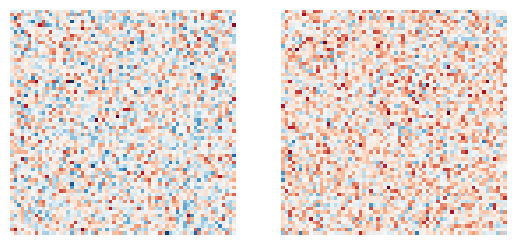

In [5]:
import numpy as np
import matplotlib.pyplot as plt

noise = np.random.randn(2, 64, 64)

fig, axes = plt.subplots(1, 2)
for ax, img in zip(axes, noise):
    im = ax.imshow(img, cmap='RdBu_r')
    ax.axis('off')

plt.show()